
# Electricity Price Forecasting Experiments

## Germany–Luxembourg Electricity Market

**Objective:** Predict hourly electricity prices 24 hours ahead using historical market data.

1. Prepare the forecasting dataset.
2. Split data chronologically.
3. Train forecasting models.
4. Compare their performance.
5. Select a model for deployment.


In [1]:

from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))

from src.forecasting.features import create_features

print("Libraries imported successfully!")


Libraries imported successfully!


LOAD THE DATA

In [2]:

DATA_PATH = (
    ROOT / "data" / "processed"
    / "germany_luxembourg_analytics.parquet"
)

df = pd.read_parquet(DATA_PATH)

features = create_features(df)

print("Dataset shape:", features.shape)
print("Date range:", features.index.min(), "to", features.index.max())

features.head()


Dataset shape: (26136, 12)
Date range: 2023-01-07 23:00:00+00:00 to 2025-12-31 22:00:00+00:00


,price_eur_mwh,hour,day_of_week,month,is_weekend,hour_sin,hour_cos,lag_24,lag_48,lag_168,rolling_mean_24,rolling_std_24
timestamp_utc,,,,,,,,,,,,
2023-01-07 23:00:00+00:00,10.93,0,6,1,1,0.000000,1.000000,97.15,107.21,-5.17,117.054167,22.105513
2023-01-08 00:00:00+00:00,9.07,1,6,1,1,0.258819,0.965926,98.43,101.10,-1.07,116.942917,22.195830
2023-01-08 01:00:00+00:00,9.10,2,6,1,1,0.500000,0.866025,96.05,96.73,-1.47,116.914583,22.223171
2023-01-08 02:00:00+00:00,4.16,3,6,1,1,0.707107,0.707107,87.97,82.34,-5.08,117.149167,21.869237
2023-01-08 03:00:00+00:00,5.58,4,6,1,1,0.866025,0.500000,82.99,81.93,-4.49,117.193333,21.795964


Use 2023 for training, 2024 for validation, and 2025 for final testing.

In [3]:

target = "price_eur_mwh"

train = features.loc[features.index.year == 2023]
val = features.loc[features.index.year == 2024]
test = features.loc[features.index.year == 2025]

X_train = train.drop(columns=[target])
y_train = train[target]

X_val = val.drop(columns=[target])
y_val = val[target]

X_test = test.drop(columns=[target])
y_test = test[target]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)


Training: (8593, 11)
Validation: (8784, 11)
Testing: (8759, 11)


Train using HistGradientBoosting Model

In [4]:

model = HistGradientBoostingRegressor(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=31,
    random_state=42
)

model.fit(X_train, y_train)

val_predictions = model.predict(X_val)

print("Model trained successfully!")


Model trained successfully!


EVALUATE MODEL

In [5]:

mae = mean_absolute_error(y_val, val_predictions)

rmse = np.sqrt(
    mean_squared_error(y_val, val_predictions)
)

baseline_mae = mean_absolute_error(
    y_val,
    X_val["lag_24"]
)

print(f"Model MAE: €{mae:.2f}/MWh")
print(f"Model RMSE: €{rmse:.2f}/MWh")
print(f"Baseline MAE: €{baseline_mae:.2f}/MWh")
print(f"Improvement: {(baseline_mae - mae) / baseline_mae * 100:.1f}%")


Model MAE: €24.45/MWh
Model RMSE: €38.49/MWh
Baseline MAE: €27.82/MWh
Improvement: 12.1%


Compare using Random Forest forecasting model

In [6]:

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_val)

rf_mae = mean_absolute_error(y_val, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_val, rf_predictions))

comparison = pd.DataFrame({
    "Model": [
        "Historical Baseline",
        "HistGradientBoosting",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        mae,
        rf_mae
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_val, X_val["lag_24"])),
        rmse,
        rf_rmse
    ]
})

comparison.sort_values("MAE")


,Model,MAE,RMSE
2,Random Forest,23.891257,37.927062
1,HistGradientBoosting,24.451386,38.485905
0,Historical Baseline,27.818939,44.305339


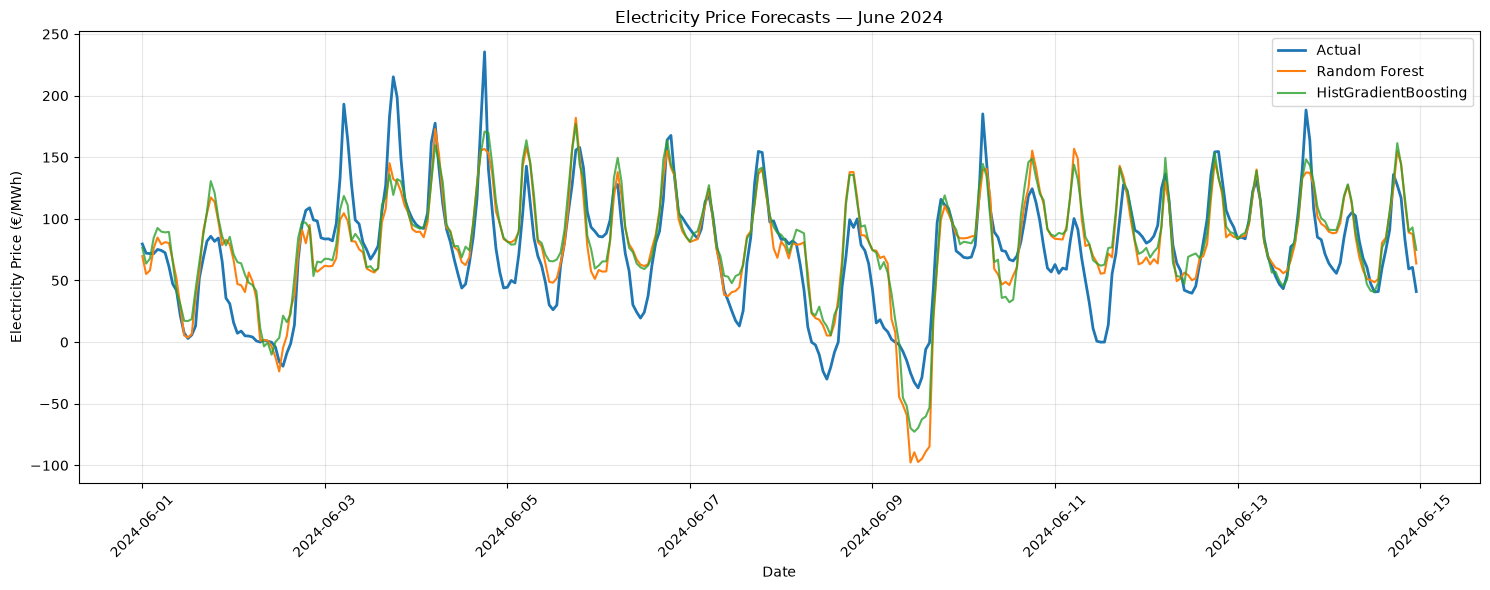

In [7]:

# Compare actual and predicted prices for June 2024

results = pd.DataFrame({
    "actual": y_val,
    "random_forest": rf_predictions,
    "hist_gradient_boosting": val_predictions
}, index=y_val.index)

sample = results.loc["2024-06-01":"2024-06-14"]

plt.figure(figsize=(15, 6))

plt.plot(
    sample.index,
    sample["actual"],
    label="Actual",
    linewidth=2
)

plt.plot(
    sample.index,
    sample["random_forest"],
    label="Random Forest",
    linewidth=1.5
)

plt.plot(
    sample.index,
    sample["hist_gradient_boosting"],
    label="HistGradientBoosting",
    linewidth=1.5,
    alpha=0.8
)

plt.title("Electricity Price Forecasts — June 2024")
plt.xlabel("Date")
plt.ylabel("Electricity Price (€/MWh)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [8]:

# Analyze forecasting errors under different market conditions

analysis = results.copy()

analysis["rf_absolute_error"] = (
    analysis["actual"] - analysis["random_forest"]
).abs()

analysis["price_category"] = pd.cut(
    analysis["actual"],
    bins=[-float("inf"), 0, 50, 100, 150, float("inf")],
    labels=[
        "Negative",
        "0-50",
        "50-100",
        "100-150",
        "Above 150"
    ]
)

error_by_category = (
    analysis.groupby(
        "price_category",
        observed=True
    )["rf_absolute_error"]
    .agg(["count", "mean", "median"])
)

error_by_category


,count,mean,median
price_category,,,
Negative,519,43.994678,44.110393
0-50,1356,32.737678,29.936426
50-100,4613,16.991268,12.726914
100-150,1935,19.175178,15.149034
Above 150,361,75.209376,47.772365


Key findings
- Normal market conditions: The model performs reasonably well.
- Negative prices: Errors increase substantially.
- Extreme price spikes: The model struggles the most, with €75.21/MWh average error.
- Main weakness: The model learns regular price patterns but has difficulty predicting unusual market conditions.

## Feature Engineering — Version 2

Add historical price trends, volatility, and calendar features to improve 24-hour-ahead forecasting.

STEP 1: CREATE ENHANCED FEATURES

In [9]:

# Start from the original feature dataset
features_v2 = features.copy()

prices = df["price_eur_mwh"].sort_index()

# Historical prices available 24 hours before target
history = prices.shift(24)

# Longer-term price trends
features_v2["rolling_mean_48"] = (
    history.rolling(48).mean()
)

features_v2["rolling_mean_168"] = (
    history.rolling(168).mean()
)

# Historical volatility
features_v2["rolling_std_48"] = (
    history.rolling(48).std()
)

features_v2["rolling_std_168"] = (
    history.rolling(168).std()
)

# Historical minimum and maximum
features_v2["rolling_min_168"] = (
    history.rolling(168).min()
)

features_v2["rolling_max_168"] = (
    history.rolling(168).max()
)

# Additional calendar features
local_time = features_v2.index.tz_convert("Europe/Berlin")

features_v2["day_of_year"] = local_time.dayofyear

features_v2["day_of_year_sin"] = np.sin(
    2 * np.pi * features_v2["day_of_year"] / 365.25
)

features_v2["day_of_year_cos"] = np.cos(
    2 * np.pi * features_v2["day_of_year"] / 365.25
)

# Remove rows without sufficient historical data
features_v2 = features_v2.dropna()

print("Original shape:", features.shape)
print("Enhanced shape:", features_v2.shape)
print("Missing values:", features_v2.isna().sum().sum())


Original shape: (26136, 12)
Enhanced shape: (26113, 21)
Missing values: 0


C:\Users\User\AppData\Local\Temp\ipykernel_344\2118906663.py:39: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  features_v2["day_of_year"] = local_time.dayofyear


Step 2 — Retrain Random Forest
We'll use the same training and validation years.

In [10]:

train_v2 = features_v2.loc[
    features_v2.index.year == 2023
]

val_v2 = features_v2.loc[
    features_v2.index.year == 2024
]

X_train_v2 = train_v2.drop(columns=["price_eur_mwh"])
y_train_v2 = train_v2["price_eur_mwh"]

X_val_v2 = val_v2.drop(columns=["price_eur_mwh"])
y_val_v2 = val_v2["price_eur_mwh"]

rf_v2 = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

rf_v2.fit(X_train_v2, y_train_v2)

pred_v2 = rf_v2.predict(X_val_v2)

mae_v2 = mean_absolute_error(y_val_v2, pred_v2)

rmse_v2 = np.sqrt(
    mean_squared_error(y_val_v2, pred_v2)
)

print(f"Enhanced Random Forest MAE: €{mae_v2:.2f}/MWh")
print(f"Enhanced Random Forest RMSE: €{rmse_v2:.2f}/MWh")


Enhanced Random Forest MAE: €27.05/MWh
Enhanced Random Forest RMSE: €41.12/MWh


Step 3 — Compare fairly with the original model  
The enhanced features remove some additional early training rows.   
To ensure a fair validation comparison, evaluate both models on the same timestamps.

In [11]:

# Align the original model's predictions with V2 validation
original_predictions = pd.Series(
    rf_predictions,
    index=y_val.index
).loc[y_val_v2.index]

original_mae = mean_absolute_error(
    y_val_v2,
    original_predictions
)

comparison_v2 = pd.DataFrame({
    "Model": ["Original Random Forest", "Enhanced Random Forest"],
    "MAE": [original_mae, mae_v2],
    "RMSE": [
        np.sqrt(mean_squared_error(y_val_v2, original_predictions)),
        rmse_v2
    ]
})

comparison_v2


,Model,MAE,RMSE
0,Original Random Forest,23.891257,37.927062
1,Enhanced Random Forest,27.048431,41.120285


_______

## Test XGBoost

In [ ]:
%pip install xgboost

In [15]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=500,
    max_depth=4,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Use original features, not enhanced features
xgb_model.fit(X_train, y_train)

xgb_predictions = xgb_model.predict(X_val)

xgb_mae = mean_absolute_error(y_val, xgb_predictions)
xgb_rmse = np.sqrt(
    mean_squared_error(y_val, xgb_predictions)
)

comparison = pd.DataFrame({
    "Model": [
        "Historical Baseline",
        "HistGradientBoosting",
        "Random Forest",
        "Enhanced Random Forest",
        "XGBoost"
    ],
    "MAE": [
        baseline_mae,
        mae,
        rf_mae,
        mae_v2,
        xgb_mae
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_val, X_val["lag_24"])),
        rmse,
        rf_rmse,
        rmse_v2,
        xgb_rmse
    ]
})

comparison.sort_values("MAE")


,Model,MAE,RMSE
4,XGBoost,23.345064,37.842057
2,Random Forest,23.891257,37.927062
1,HistGradientBoosting,24.451386,38.485905
3,Enhanced Random Forest,27.048431,41.120285
0,Historical Baseline,27.818939,44.305339


___________

Convert 15-minute forecasts to hourly
Our existing electricity price dataset is hourly, so we need to align these datasets.

For power forecasts measured in MW, we'll use the average of the four 15-minute values within each hour.

In [16]:

# Load the new market forecasts

forecast_dir = ROOT / "data" / "raw" / "entsoe"

load = pd.read_parquet(
    forecast_dir / "de_lu_load_forecast_2024_test.parquet"
)

renewables = pd.read_parquet(
    forecast_dir / "de_lu_wind_solar_forecast_2024_test.parquet"
)

# Convert 15-minute MW forecasts to hourly averages
load_hourly = load.resample("h").mean()
renewables_hourly = renewables.resample("h").mean()

# Combine market features
market_features = pd.DataFrame(index=load_hourly.index)

market_features["load_forecast_mw"] = (
    load_hourly["Forecasted Load"]
)

market_features["solar_forecast_mw"] = (
    renewables_hourly["Solar"]
)

market_features["wind_forecast_mw"] = (
    renewables_hourly["Wind Offshore"]
    + renewables_hourly["Wind Onshore"]
)

# Validate the result
print("Shape:", market_features.shape)
print("Missing values:")
print(market_features.isna().sum())
print("Time intervals:")
print(market_features.index.to_series().diff().value_counts())

market_features.head()


Shape: (168, 3)
Missing values:
load_forecast_mw     0
solar_forecast_mw    0
wind_forecast_mw     0
dtype: int64
Time intervals:
timestamp_utc
0 days 01:00:00    167
Name: count, dtype: int64


,load_forecast_mw,solar_forecast_mw,wind_forecast_mw
timestamp_utc,,,
2023-12-31 23:00:00+00:00,39981.7075,0.0,35376.6625
2024-01-01 00:00:00+00:00,38085.8375,0.0,34897.8200
2024-01-01 01:00:00+00:00,37063.4575,0.0,34576.8850
2024-01-01 02:00:00+00:00,36834.3650,0.0,34137.8950
2024-01-01 03:00:00+00:00,36835.2225,0.0,33765.0500


## Inspect missing timestamps from Market Forecasts Downloaded Dataset 

In [18]:

from pathlib import Path
import pandas as pd

DATA_DIR = ROOT / "data" / "raw" / "entsoe"

for year in [2023, 2024, 2025]:
    print(f"\n========== {year} ==========")

    start = pd.Timestamp(
        f"{year}-01-01", tz="Europe/Berlin"
    ).tz_convert("UTC")

    end = pd.Timestamp(
        f"{year + 1}-01-01", tz="Europe/Berlin"
    ).tz_convert("UTC")

    expected = pd.date_range(
        start, end, freq="15min", inclusive="left"
    )

    for name in ["load_forecast", "wind_solar_forecast"]:
        files = sorted(
            DATA_DIR.glob(f"de_lu_{name}_{year}_??.parquet")
        )

        data = pd.concat(
            [pd.read_parquet(f) for f in files]
        ).sort_index()

        missing_times = expected.difference(data.index)

        print(f"\n{name}")

        if len(missing_times):
            print("Missing timestamps:")
            print(missing_times)

        missing_values = data[data.isna().any(axis=1)]

        if not missing_values.empty:
            print("Rows containing missing values:")
            print(missing_values)



========== 2023 ==========

load_forecast
Missing timestamps:
DatetimeIndex(['2023-10-28 22:00:00+00:00', '2023-10-28 22:15:00+00:00',
               '2023-10-28 22:30:00+00:00', '2023-10-28 22:45:00+00:00'],
              dtype='datetime64[us, UTC]', freq='15min')

wind_solar_forecast
Rows containing missing values:
                           Solar  Wind Offshore  Wind Onshore
timestamp_utc                                                
2023-10-28 22:00:00+00:00    NaN        5237.01           NaN
2023-10-28 22:15:00+00:00    NaN        5291.42           NaN
2023-10-28 22:30:00+00:00    NaN        5348.94           NaN
2023-10-28 22:45:00+00:00    NaN        5402.62           NaN

========== 2024 ==========

load_forecast
Missing timestamps:
DatetimeIndex(['2024-10-26 22:00:00+00:00', '2024-10-26 22:15:00+00:00',
               '2024-10-26 22:30:00+00:00', '2024-10-26 22:45:00+00:00'],
              dtype='datetime64[us, UTC]', freq='15min')

wind_solar_forecast
Rows containing miss

To check that the market data aligns correctly with electricity prices.

In [19]:

import pandas as pd
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

prices = pd.read_parquet(
    ROOT / "data/processed/germany_luxembourg_analytics.parquet"
)

market = pd.read_parquet(
    ROOT / "data/processed/germany_luxembourg_market_features.parquet"
)

combined = prices[["price_eur_mwh"]].join(
    market,
    how="left"
)

print("Combined shape:", combined.shape)
print("\nMissing values:")
print(combined.isna().sum())

print("\nDate range:")
print(combined.index.min(), "to", combined.index.max())

print("\nSample:")
display(combined.head())


Combined shape: (26304, 4)

Missing values:
price_eur_mwh        0
load_forecast_mw     2
solar_forecast_mw    3
wind_forecast_mw     3
dtype: int64

Date range:
2022-12-31 23:00:00+00:00 to 2025-12-31 22:00:00+00:00

Sample:


,price_eur_mwh,load_forecast_mw,solar_forecast_mw,wind_forecast_mw
timestamp_utc,,,,
2022-12-31 23:00:00+00:00,-5.17,42215.4725,0.0,39002.5525
2023-01-01 00:00:00+00:00,-1.07,40026.9350,0.0,38805.6225
2023-01-01 01:00:00+00:00,-1.47,38631.0300,0.0,38542.2325
2023-01-01 02:00:00+00:00,-5.08,37588.6625,0.0,37858.9700
2023-01-01 03:00:00+00:00,-4.49,37705.7350,0.0,37336.2900


## Build leakage-safe price-history features  

Electricity prices wouldn't have been known when the forecast was issued.

For this experiment, we'll assume a daily forecast is generated at 09:00 Germany time, predicting all 24 hours of the following day.

This is a modelling assumption, not yet a verified ENTSO-E publication cutof
It tells us whether the additional market variables have predictive value, but not yet how well a real-time forecasting system would perform.

In [20]:

import numpy as np
import pandas as pd

data = combined.copy().sort_index()

# Convert delivery timestamps to German local time
local = data.index.tz_convert("Europe/Berlin")

data["delivery_date"] = pd.to_datetime(
    local.date
)

data["hour"] = local.hour
data["day_of_week"] = local.day_of_week
data["month"] = local.month

# Previous-day and previous-week prices must be
# computed relative to the forecast issuance cutoff.
#
# For a forecast issued at 09:00 on D-1:
# the latest fully known local day is D-2.

daily = data.groupby("delivery_date")["price_eur_mwh"]

daily_stats = daily.agg(
    daily_mean="mean",
    daily_min="min",
    daily_max="max",
    daily_std="std"
)

# D-2 statistics for each delivery date D
for column in daily_stats.columns:
    data[f"known_{column}"] = (
        data["delivery_date"].map(
            daily_stats[column].shift(2)
        )
    )

print(data.shape)
display(data.head())


(26304, 12)


C:\Users\User\AppData\Local\Temp\ipykernel_344\2354464696.py:14: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  data["day_of_week"] = local.dayofweek


,price_eur_mwh,load_forecast_mw,solar_forecast_mw,wind_forecast_mw,delivery_date,hour,day_of_week,month,known_daily_mean,known_daily_min,known_daily_max,known_daily_std
timestamp_utc,,,,,,,,,,,,
2022-12-31 23:00:00+00:00,-5.17,42215.4725,0.0,39002.5525,2023-01-01,0,6,1,NaN,NaN,NaN,NaN
2023-01-01 00:00:00+00:00,-1.07,40026.9350,0.0,38805.6225,2023-01-01,1,6,1,NaN,NaN,NaN,NaN
2023-01-01 01:00:00+00:00,-1.47,38631.0300,0.0,38542.2325,2023-01-01,2,6,1,NaN,NaN,NaN,NaN
2023-01-01 02:00:00+00:00,-5.08,37588.6625,0.0,37858.9700,2023-01-01,3,6,1,NaN,NaN,NaN,NaN
2023-01-01 03:00:00+00:00,-4.49,37705.7350,0.0,37336.2900,2023-01-01,4,6,1,NaN,NaN,NaN,NaN
